<a href="https://colab.research.google.com/github/namirachmi08/Text-Clustering/blob/main/Pemteks_Movie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install datasets

import pandas as pd
from datasets import load_dataset

# Mengambil dataset ulasan film IMDb
dataset = load_dataset("stanfordnlp/imdb")

# Menggabungkan data train dan test
df = pd.concat([
    pd.DataFrame(dataset["train"]),
    pd.DataFrame(dataset["test"])
], ignore_index=True)

# Mengambil 1.000 data secara acak
df = df.sample(n=1000, random_state=42).reset_index(drop=True)

# Mengubah nama kolom dan label
df = df.rename(columns={"text": "prepro"})
df["Sentiment"] = df["label"].map({
    0: "negative",
    1: "positive"
})

df = df[["prepro", "Sentiment"]]

# Menyimpan dataset menjadi CSV
df.to_csv("movie_reviews.csv", index=False)

print("Dataset berhasil dibuat!")
print("Jumlah data:", len(df))
display(df.head())


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset berhasil dibuat!
Jumlah data: 1000


,prepro,Sentiment
0,Forget what I said about Emeril. Rachael Ray i...,negative
1,Former private eye-turned-security guard ditch...,negative
2,Mann photographs the Alberta Rocky Mountains i...,negative
3,Simply put: the movie is boring. Cliché upon c...,negative
4,"Now being a fan of sci fi, the trailer for thi...",positive


In [ ]:
from google.colab import files
files.download("movie_reviews.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# PREPROCESSING TEXT: LOWERCASE, CLEANING, PUNCTUATION REMOVAL, DAN STOPWORD REMOVAL

import pandas as pd
import re
import nltk
from nltk.corpus import stopwords

# Mengunduh stopword bahasa Inggris
nltk.download("stopwords")

# 1. Membaca dataset
df = pd.read_csv("movie_reviews.csv")
df = df.dropna(subset=["prepro", "Sentiment"]).reset_index(drop=True)

# 2. Mengambil stopword bahasa Inggris
stop_words = set(stopwords.words("english"))

# Mempertahankan kata penting untuk sentimen
stop_words = stop_words - {"not", "no", "nor"}

# 3. Membuat fungsi preprocessing
def preprocessing(text):
    # Mengubah teks menjadi huruf kecil
    text = text.lower()

    # Menghapus tag HTML
    text = re.sub(r"<br\s*/?>", " ", text)

    # Menghapus URL
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Menghapus angka dan tanda baca
    text = re.sub(r"[^a-z\s]", " ", text)

    # Menghapus spasi berlebih
    text = re.sub(r"\s+", " ", text).strip()

    # Menghapus stopword
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

# 4. Menerapkan preprocessing pada teks
df["prepro"] = df["prepro"].astype(str).apply(preprocessing)

# 5. Menghapus teks yang kosong setelah preprocessing
df = df[df["prepro"].str.strip() != ""].reset_index(drop=True)

# 6. Membuat salinan khusus untuk tampilan
df_tampil = df[["prepro", "Sentiment"]].copy()

# Menampilkan maksimal 20 kata dari setiap ulasan
df_tampil["prepro"] = df_tampil["prepro"].apply(
    lambda text: " ".join(text.split()[:20]) + "..."
    if len(text.split()) > 20 else text)

# 7. Menampilkan hasil preprocessing
pd.set_option("display.max_colwidth", 150)

print("Jumlah data setelah preprocessing:", len(df))
print("\nContoh hasil preprocessing:")

display(df_tampil.head(10))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Jumlah data setelah preprocessing: 1000

Contoh hasil preprocessing:


,prepro,Sentiment
0,forget said emeril rachael ray irritating personality food network television never seen minute meals cannot possibly begin comprehend unfathomabl...,negative
1,former private eye turned security guard ditches latest droning job immediately offered chance return previous profession assignment tail mysterio...,negative
2,mann photographs alberta rocky mountains superb fashion jimmy stewart walter brennan give enjoyable performances always seem come hollywood mounti...,negative
3,simply put movie boring clich upon clich confirmed story lines never come together seems director unsure whether make movie documentary...,negative
4,fan sci fi trailer film looked bit put hollywood watching gladly say impressed greatly jude class actor miss leigh pulls...,positive
5,hoot logan lerman plays roy eberhardt new kid school moved montana florida lot different montana despite troubles blending roy discovers...,positive
6,worst film ever seen watching film friends minutes enough plot bad single likeable character could get entertainment watching static gave...,negative
7,think toy soldiers excellent movie one movies aside well known actors unknown cast actually act opinion plot captivating keeps attention...,positive
8,think micheal ironsides acting career must star sort low budge crap surely could better waste time rubbish movie could far...,negative
9,disgrace game farcry much expectations ended nightmare besides bad acting visual effects stunts plot even humor used movie absolute flop...,negative


In [ ]:
# FEATURE ENGINEERING: TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Mengubah teks menjadi fitur numerik
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(df["prepro"])

# Mengubah hasil TF-IDF menjadi DataFrame
df_FE = pd.DataFrame(
    X.toarray(),
    columns=vectorizer.get_feature_names_out())

print("Ukuran matriks TF-IDF:", X.shape)
print("Jumlah fitur:", len(vectorizer.get_feature_names_out()))

display(df_FE.head())

Ukuran matriks TF-IDF: (1000, 5000)
Jumlah fitur: 5000


,aaron,abandon,abandoned,abc,abduction,ability,abishag,abject,able,ably,...,younger,youth,yuppie,zak,zechs,zed,zero,zoe,zombie,zombies
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


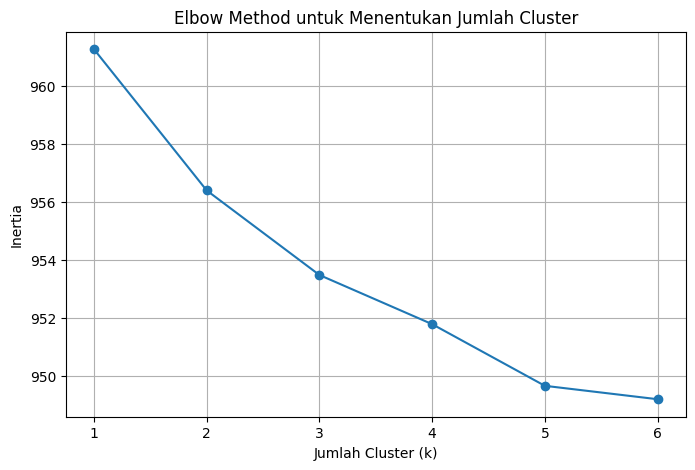

In [ ]:
# ELBOW METHOD

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertia = []
k_values = range(1, 7)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=10,
        n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia, marker="o")
plt.title("Elbow Method untuk Menentukan Jumlah Cluster")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
# K-MEANS CLUSTERING

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(
    n_clusters=4,
    random_state=10,
    n_init=10)

df["KMeans_Cluster"] = kmeans.fit_predict(X)

# Menghitung Silhouette Score
silhouette = silhouette_score(
    X,
    df["KMeans_Cluster"],
    sample_size=min(500, X.shape[0]),
    random_state=10)

print("Silhouette Score K-Means:", silhouette)
print("\nJumlah data pada setiap cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())

display(df[["prepro", "Sentiment", "KMeans_Cluster"]].head(10))

Silhouette Score K-Means: 0.001912766951342048

Jumlah data pada setiap cluster:
KMeans_Cluster
0    115
1    212
2    407
3    266
Name: count, dtype: int64


,prepro,Sentiment,KMeans_Cluster
0,forget said emeril rachael ray irritating personality food network television never seen minute meals cannot possibly begin comprehend unfathomabl...,negative,2
1,former private eye turned security guard ditches latest droning job immediately offered chance return previous profession assignment tail mysterio...,negative,0
2,mann photographs alberta rocky mountains superb fashion jimmy stewart walter brennan give enjoyable performances always seem come hollywood mounti...,negative,2
3,simply put movie boring clich upon clich confirmed story lines never come together seems director unsure whether make movie documentary main plot ...,negative,3
4,fan sci fi trailer film looked bit put hollywood watching gladly say impressed greatly jude class actor miss leigh pulls better delores clairborne...,positive,1
5,hoot logan lerman plays roy eberhardt new kid school moved montana florida lot different montana despite troubles blending roy discovers bigger pr...,positive,0
6,worst film ever seen watching film friends minutes enough plot bad single likeable character could get entertainment watching static gave movie sc...,negative,1
7,think toy soldiers excellent movie one movies aside well known actors unknown cast actually act opinion plot captivating keeps attention without o...,positive,3
8,think micheal ironsides acting career must star sort low budge crap surely could better waste time rubbish movie could far better good budget show...,negative,3
9,disgrace game farcry much expectations ended nightmare besides bad acting visual effects stunts plot even humor used movie absolute flop movie not...,negative,3


In [ ]:
# AGGLOMERATIVE CLUSTERING

from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Mengurangi dimensi fitur TF-IDF
svd = TruncatedSVD(n_components=100, random_state=10)
X_svd = svd.fit_transform(X)

# Membentuk cluster
agg = AgglomerativeClustering(n_clusters=4)
df["Agglomerative_Cluster"] = agg.fit_predict(X_svd)

# Menghitung Silhouette Score
silhouette_agg = silhouette_score(
    X_svd,
    df["Agglomerative_Cluster"],
    sample_size=min(500, X_svd.shape[0]),
    random_state=10)

print("Silhouette Score Agglomerative:", silhouette_agg)
print("\nJumlah data pada setiap cluster:")
print(df["Agglomerative_Cluster"].value_counts().sort_index())

display(
    df[["prepro", "Sentiment", "Agglomerative_Cluster"]].head(10))

Silhouette Score Agglomerative: 0.006668666506839146

Jumlah data pada setiap cluster:
Agglomerative_Cluster
0    401
1    409
2     34
3    156
Name: count, dtype: int64


,prepro,Sentiment,Agglomerative_Cluster
0,forget said emeril rachael ray irritating personality food network television never seen minute meals cannot possibly begin comprehend unfathomabl...,negative,1
1,former private eye turned security guard ditches latest droning job immediately offered chance return previous profession assignment tail mysterio...,negative,0
2,mann photographs alberta rocky mountains superb fashion jimmy stewart walter brennan give enjoyable performances always seem come hollywood mounti...,negative,1
3,simply put movie boring clich upon clich confirmed story lines never come together seems director unsure whether make movie documentary main plot ...,negative,1
4,fan sci fi trailer film looked bit put hollywood watching gladly say impressed greatly jude class actor miss leigh pulls better delores clairborne...,positive,0
5,hoot logan lerman plays roy eberhardt new kid school moved montana florida lot different montana despite troubles blending roy discovers bigger pr...,positive,1
6,worst film ever seen watching film friends minutes enough plot bad single likeable character could get entertainment watching static gave movie sc...,negative,0
7,think toy soldiers excellent movie one movies aside well known actors unknown cast actually act opinion plot captivating keeps attention without o...,positive,3
8,think micheal ironsides acting career must star sort low budge crap surely could better waste time rubbish movie could far better good budget show...,negative,0
9,disgrace game farcry much expectations ended nightmare besides bad acting visual effects stunts plot even humor used movie absolute flop movie not...,negative,0


,Metode,Silhouette Score
0,K-Means,0.001913
1,Agglomerative,0.006669


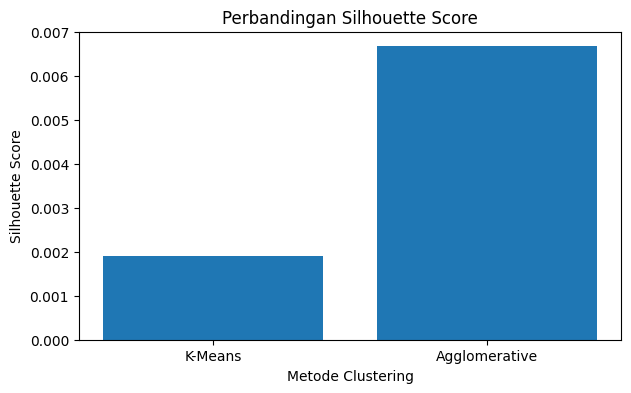

In [ ]:
# PERBANDINGAN HASIL CLUSTERING

hasil_clustering = pd.DataFrame({
    "Metode": ["K-Means", "Agglomerative"],
    "Silhouette Score": [silhouette, silhouette_agg]})

display(hasil_clustering)

plt.figure(figsize=(7, 4))
plt.bar(
    hasil_clustering["Metode"],
    hasil_clustering["Silhouette Score"])
plt.title("Perbandingan Silhouette Score")
plt.xlabel("Metode Clustering")
plt.ylabel("Silhouette Score")
plt.show()

In [ ]:
# ANALISIS SENTIMEN SETIAP CLUSTER K-MEANS

tabel_sentimen = pd.crosstab(
    df["KMeans_Cluster"],
    df["Sentiment"])

display(tabel_sentimen)

# Menghitung persentase sentimen dalam setiap cluster
persentase_sentimen = pd.crosstab(
    df["KMeans_Cluster"],
    df["Sentiment"],
    normalize="index") * 100

display(persentase_sentimen.round(2))

Sentiment,negative,positive
KMeans_Cluster,,
0,41,74
1,108,104
2,209,198
3,152,114


Sentiment,negative,positive
KMeans_Cluster,,
0,35.65,64.35
1,50.94,49.06
2,51.35,48.65
3,57.14,42.86


In [ ]:
print("Silhouette Score K-Means:", silhouette)
print("Silhouette Score Agglomerative:", silhouette_agg)

Silhouette Score K-Means: 0.001912766951342048
Silhouette Score Agglomerative: 0.006668666506839146


Jumlah data setiap cluster:
KMeans_Cluster
2    407
3    266
1    212
0    115
Name: count, dtype: int64


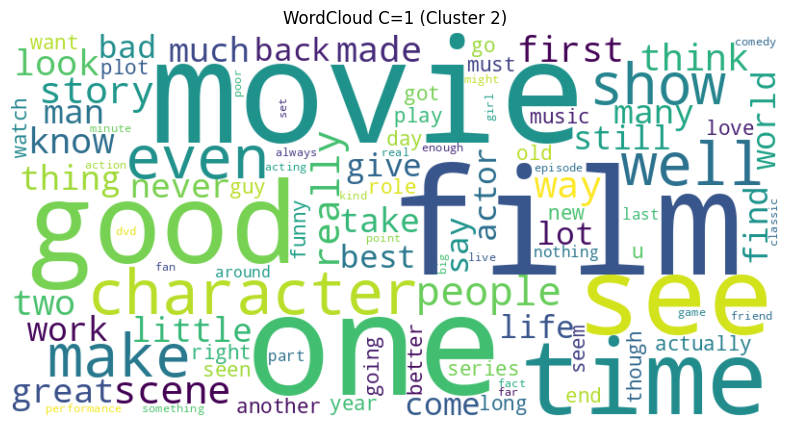

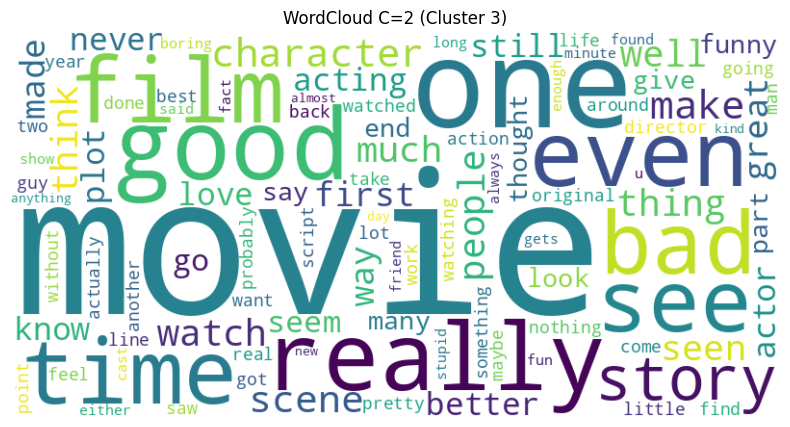

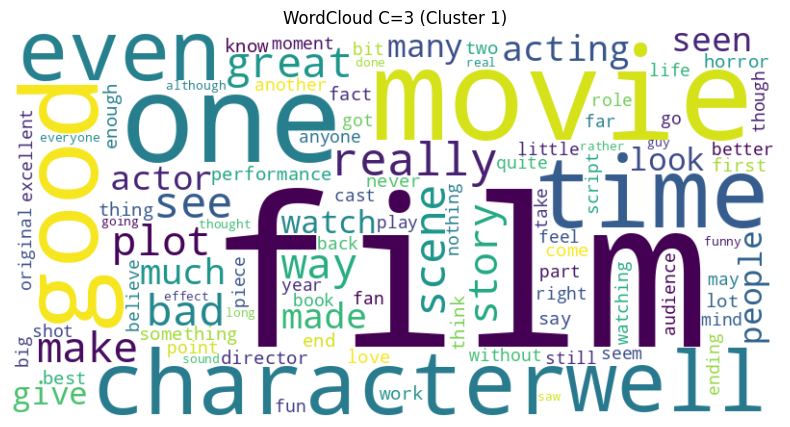

In [ ]:
# WORDCLOUD K-MEANS BERDASARKAN 3 CLUSTER TERBESAR

from sklearn.cluster import KMeans
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Membentuk 4 cluster seperti percobaan K-Means sebelumnya
kmeans = KMeans(
    n_clusters=4,
    random_state=10,
    n_init=10)

df["KMeans_Cluster"] = kmeans.fit_predict(X)

# Mengurutkan cluster berdasarkan jumlah anggota
jumlah_cluster = df["KMeans_Cluster"].value_counts()
cluster_terbesar = jumlah_cluster.index.tolist()

print("Jumlah data setiap cluster:")
print(jumlah_cluster)

# Membuat 3 WordCloud dari 3 cluster terbesar
for i, cluster in enumerate(cluster_terbesar[:3], start=1):
    teks = " ".join(
        df.loc[df["KMeans_Cluster"] == cluster, "prepro"])

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        max_words=100).generate(teks)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"WordCloud C={i} (Cluster {cluster})")
    plt.show()

In [ ]:
# UNSUPERVISED LEARNING: HIERARCHICAL CLUSTERING

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Membentuk 3 cluster menggunakan fitur hasil SVD
hierarchical = AgglomerativeClustering(n_clusters=3)
df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_svd)

# Menampilkan jumlah data per cluster
print("Jumlah data setiap cluster:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

# Menghitung Silhouette Score
score_hierarchical = silhouette_score(
    X_svd,
    df["Hierarchical_Cluster"],
    sample_size=min(500, X_svd.shape[0]),
    random_state=10)

print("Silhouette Score:", score_hierarchical)

# Menampilkan contoh hasil
display(
    df[["prepro", "Sentiment", "Hierarchical_Cluster"]].head(10))


Jumlah data setiap cluster:
Hierarchical_Cluster
0    810
1    156
2     34
Name: count, dtype: int64
Silhouette Score: 0.02724022232539214


,prepro,Sentiment,Hierarchical_Cluster
0,forget said emeril rachael ray irritating personality food network television never seen minute meals cannot possibly begin comprehend unfathomabl...,negative,0
1,former private eye turned security guard ditches latest droning job immediately offered chance return previous profession assignment tail mysterio...,negative,0
2,mann photographs alberta rocky mountains superb fashion jimmy stewart walter brennan give enjoyable performances always seem come hollywood mounti...,negative,0
3,simply put movie boring clich upon clich confirmed story lines never come together seems director unsure whether make movie documentary main plot ...,negative,0
4,fan sci fi trailer film looked bit put hollywood watching gladly say impressed greatly jude class actor miss leigh pulls better delores clairborne...,positive,0
5,hoot logan lerman plays roy eberhardt new kid school moved montana florida lot different montana despite troubles blending roy discovers bigger pr...,positive,0
6,worst film ever seen watching film friends minutes enough plot bad single likeable character could get entertainment watching static gave movie sc...,negative,0
7,think toy soldiers excellent movie one movies aside well known actors unknown cast actually act opinion plot captivating keeps attention without o...,positive,1
8,think micheal ironsides acting career must star sort low budge crap surely could better waste time rubbish movie could far better good budget show...,negative,0
9,disgrace game farcry much expectations ended nightmare besides bad acting visual effects stunts plot even humor used movie absolute flop movie not...,negative,0


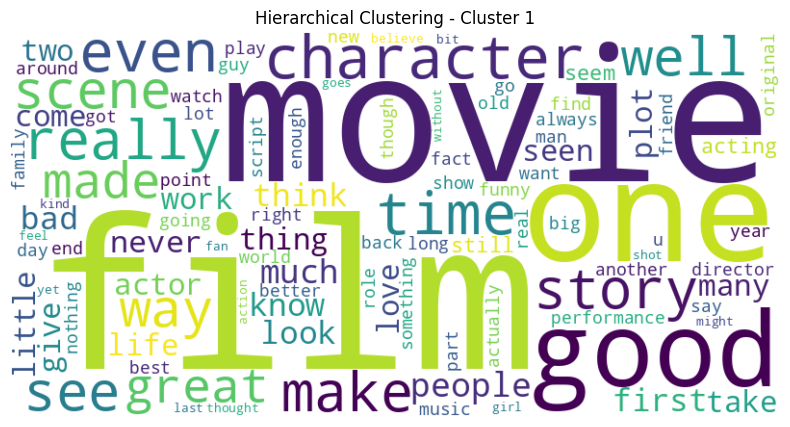

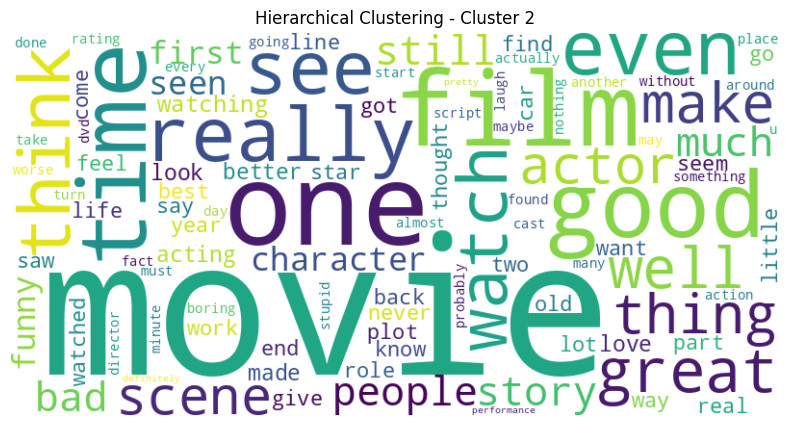

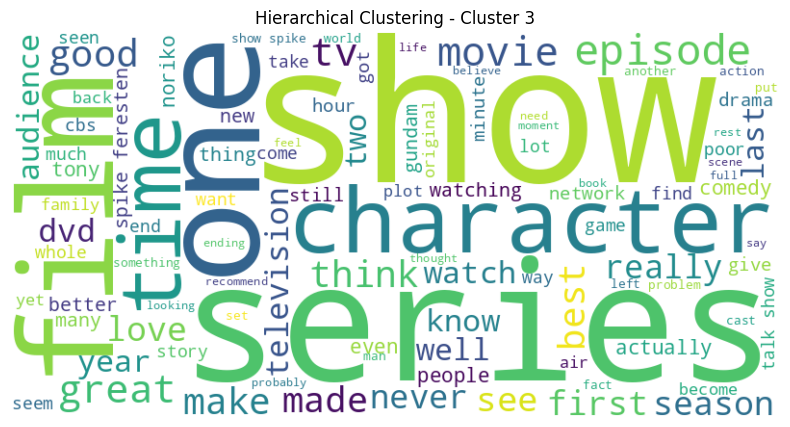

In [ ]:
# WORDCLOUD HIERARCHICAL CLUSTERING

from wordcloud import WordCloud
import matplotlib.pyplot as plt

for cluster in sorted(df["Hierarchical_Cluster"].unique()):
    teks = " ".join(
        df.loc[
            df["Hierarchical_Cluster"] == cluster,
            "prepro"])

    if teks.strip():
        wordcloud = WordCloud(
            width=800,
            height=400,
            background_color="white",
            max_words=100).generate(teks)

        plt.figure(figsize=(10, 5))
        plt.imshow(wordcloud, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"Hierarchical Clustering - Cluster {cluster + 1}")
        plt.show()


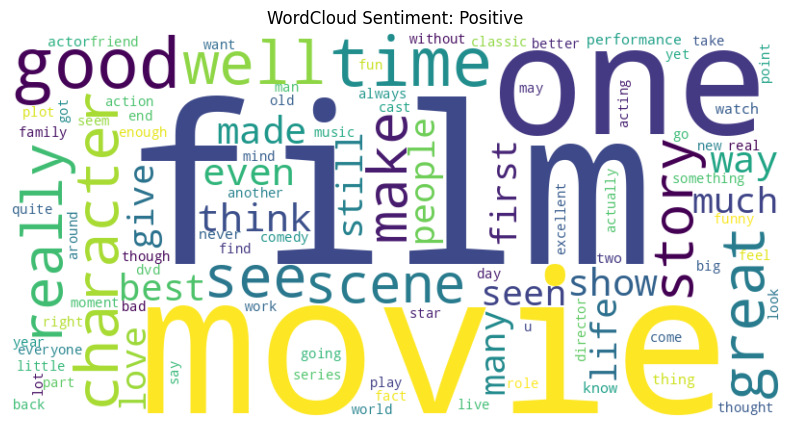

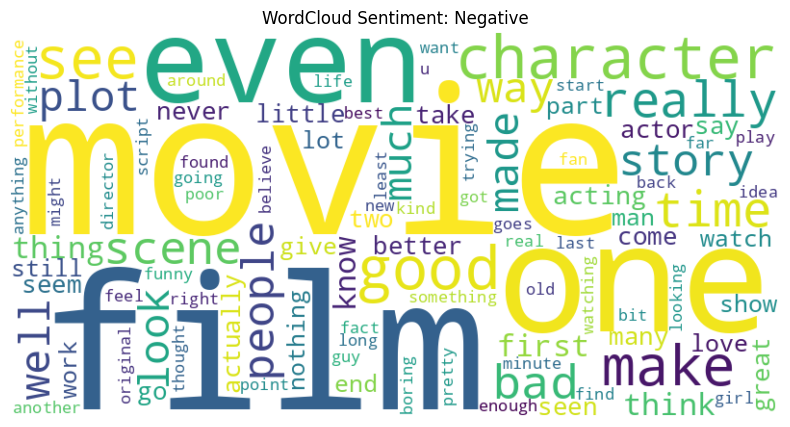

In [ ]:
# WORDCLOUD SENTIMEN POSITIF DAN NEGATIF

from wordcloud import WordCloud
import matplotlib.pyplot as plt

for sentiment in ["positive", "negative"]:
    teks = " ".join(
        df.loc[df["Sentiment"] == sentiment, "prepro"])

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        max_words=100).generate(teks)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"WordCloud Sentiment: {sentiment.capitalize()}")
    plt.show()


In [ ]:
# CLASSIFY

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
X = X  # Hasil TF-IDF dari feature engineering
y = df["Sentiment"]

# Membagi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42)

# Membuat dan melatih model Random Forest
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Melakukan prediksi pada data uji
y_pred = model.predict(X_test)

# Menampilkan hasil evaluasi
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Confusion Matrix:
[[122  24]
 [ 39 115]]

Classification Report:
              precision    recall  f1-score   support

    negative       0.76      0.84      0.79       146
    positive       0.83      0.75      0.78       154

    accuracy                           0.79       300
   macro avg       0.79      0.79      0.79       300
weighted avg       0.79      0.79      0.79       300



In [ ]:
testing = "the movie was very good, smooth, and enjoyable"
testing = vectorizer.transform([testing])
testing = model.predict(testing)
print(testing)

['positive']


In [ ]:
testing = "the movie was very bad, boring, and disappointing"
testing = vectorizer.transform([testing])
testing = model.predict(testing)
print(testing)

['negative']
